In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy
import torch
import seaborn
from adaptive_nof1 import *
from adaptive_nof1.policies import *
from adaptive_nof1.helpers import *
from adaptive_nof1.inference import *
from adaptive_nof1.metrics import *
from adaptive_nof1.models import *
from matplotlib import pyplot as plt
from adaptive_nof1.patient_explorer import show_patient_explorer
import pandas

/opt/homebrew/anaconda3/envs/adaptive_nof1/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
df = pd.read_csv("../data/ASIP/data/ASIP_data_Nof1_BB.csv")
df.columns

Index(['manuscript_ID', 'current_day_of_study', 'survey1_question1_response',
       'survey1_question2_response', 'survey1_question3_response', 'weekday',
       'intervention_period', 'current_period_of_study', 'sequence',
       'current_day_of_study_harmonized', 'dem_sex_birth', 'stress_group'],
      dtype='object')

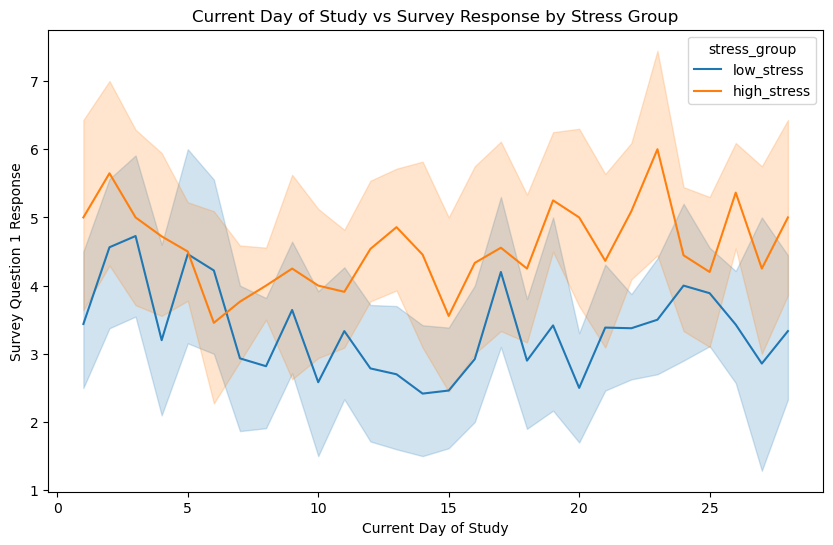

In [5]:
import seaborn as sns

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='current_day_of_study', y='survey1_question1_response', hue='stress_group')
plt.title('Current Day of Study vs Survey Response by Stress Group')
plt.xlabel('Current Day of Study')
plt.ylabel('Survey Question 1 Response')
plt.show()

Model Performance:
Mean Squared Error: 4.2291
R² Score: -0.0175


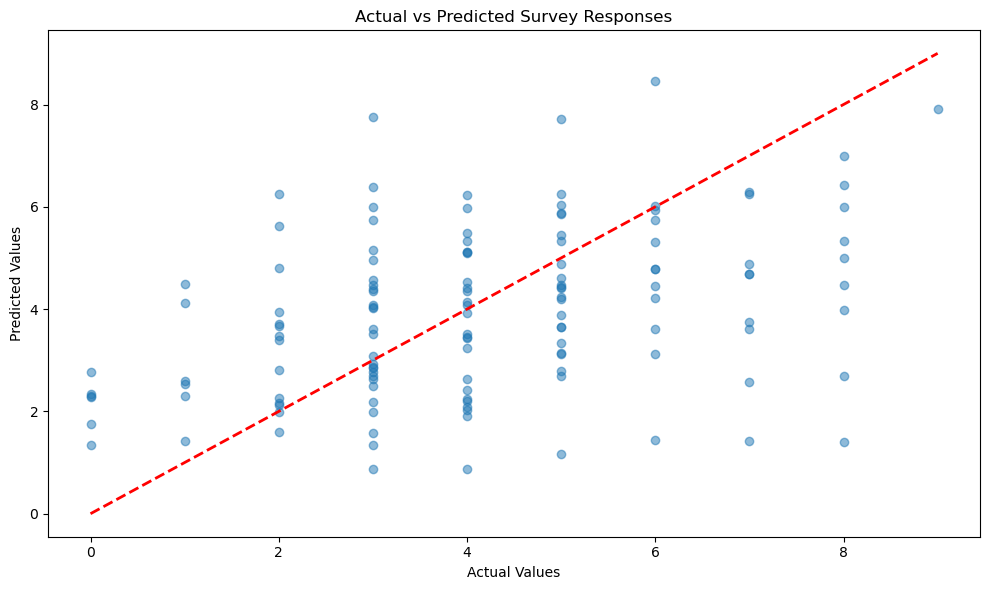

In [6]:
# Prepare data for RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

# Drop rows with missing values
df_clean = df.dropna(subset=['weekday', 'manuscript_ID', 'current_period_of_study', 'survey1_question1_response'])

# Encode categorical variables
le_manuscript = LabelEncoder()
le_period = LabelEncoder()

df_clean['manuscript_encoded'] = le_manuscript.fit_transform(df_clean['manuscript_ID'])
df_clean['period_encoded'] = le_period.fit_transform(df_clean['intervention_period'])

# Encode weekday as integer (0=Monday, 1=Tuesday, ..., 6=Sunday)
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df_clean['weekday_encoded'] = df_clean['weekday'].apply(lambda x: weekday_order.index(x) if x in weekday_order else 0)

# Prepare features and target - use only 3 columns

# Use only 3 features: weekday_encoded, manuscript_encoded, period_encoded
X = df_clean[['weekday_encoded', 'manuscript_encoded', 'period_encoded']]
y = df_clean['survey1_question1_response']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train RandomForestRegressor (no scaling needed for tree-based models)
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

# Predict and evaluate
y_pred = model.predict(X_test)

print("Model Performance:")
print(f"Mean Squared Error: {mean_squared_error(y_test, y_pred):.4f}")
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")

# Feature importance
feature_names = ['Weekday', 'Manuscript ID', 'Period of Study']
# importances = abs(model.coef_)
# for name, importance in zip(feature_names, importances):
#     print(f"{name} Importance: {importance:.4f}")

# Scatter plot of predicted vs actual values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Survey Responses')
plt.tight_layout()
plt.show()

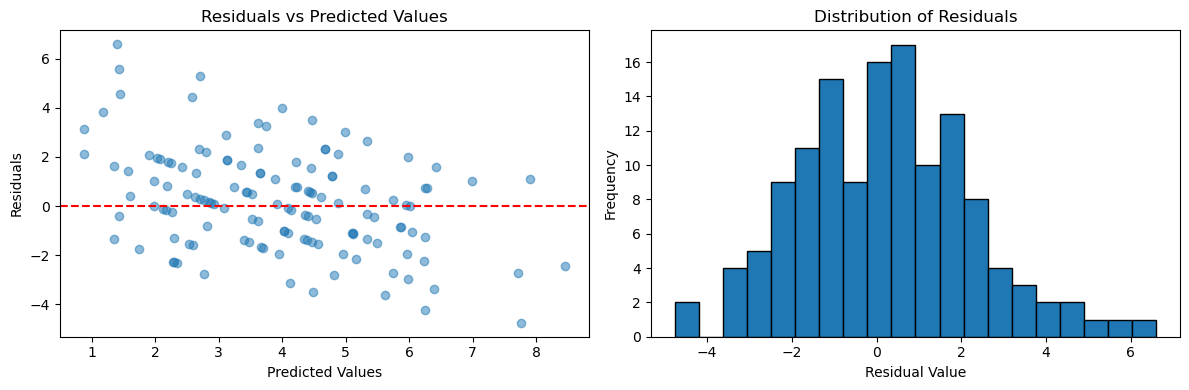


Residual Statistics:
Mean of Residuals: 0.1978
Standard Deviation of Residuals: 2.0470


In [7]:
# Residual Analysis
residuals = y_test - y_pred

# Residual Plot
plt.figure(figsize=(12, 4))

# Subplot 1: Residuals vs Predicted Values
plt.subplot(1, 2, 1)
plt.scatter(y_pred, residuals, alpha=0.5)
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Values')
plt.axhline(y=0, color='r', linestyle='--')

# Subplot 2: Histogram of Residuals
plt.subplot(1, 2, 2)
plt.hist(residuals, bins=20, edgecolor='black')
plt.xlabel('Residual Value')
plt.ylabel('Frequency')
plt.title('Distribution of Residuals')

plt.tight_layout()
plt.show()

# Additional residual diagnostics
print("\nResidual Statistics:")
print(f"Mean of Residuals: {numpy.mean(residuals):.4f}")
print(f"Standard Deviation of Residuals: {numpy.std(residuals):.4f}")

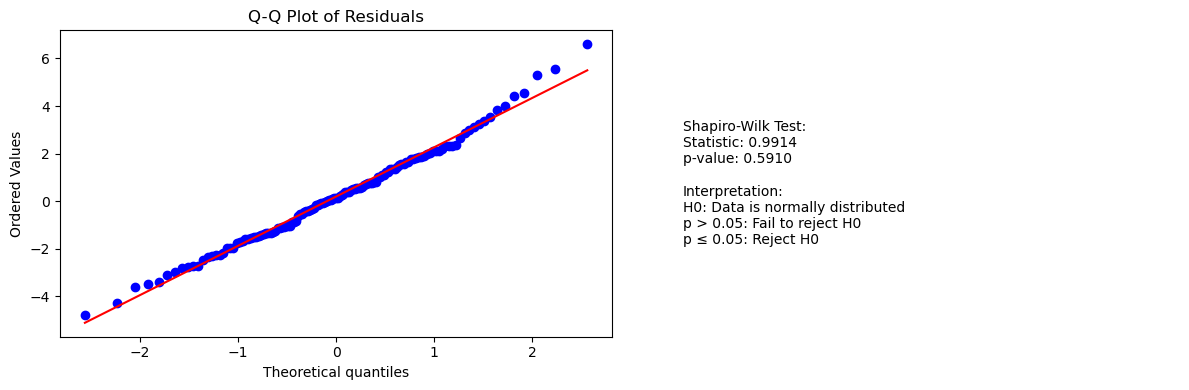


Normality Test Results:
Shapiro-Wilk Test Statistic: 0.9914
p-value: 0.5910

Residual Distribution Characteristics:
Skewness: 0.3232
Kurtosis: 0.2452


In [8]:
# Gaussian Distribution Fit Tests
from scipy import stats

# Q-Q Plot to visually check Gaussian distribution
plt.figure(figsize=(12, 4))

# Q-Q Plot
plt.subplot(1, 2, 1)
stats.probplot(residuals, dist="norm", plot=plt)
plt.title('Q-Q Plot of Residuals')

# Shapiro-Wilk Test for Normality
shapiro_test = stats.shapiro(residuals)

plt.subplot(1, 2, 2)
plt.text(0.1, 0.5, 
    f"Shapiro-Wilk Test:\n"
    f"Statistic: {shapiro_test.statistic:.4f}\n"
    f"p-value: {shapiro_test.pvalue:.4f}\n\n"
    "Interpretation:\n"
    "H0: Data is normally distributed\n"
    "p > 0.05: Fail to reject H0\n"
    "p ≤ 0.05: Reject H0", 
    fontsize=10, 
    verticalalignment='center'
)
plt.axis('off')

plt.tight_layout()
plt.show()

# Print detailed normality test results
print("\nNormality Test Results:")
print(f"Shapiro-Wilk Test Statistic: {shapiro_test.statistic:.4f}")
print(f"p-value: {shapiro_test.pvalue:.4f}")

# Additional normality metrics
print("\nResidual Distribution Characteristics:")
print(f"Skewness: {stats.skew(residuals):.4f}")
print(f"Kurtosis: {stats.kurtosis(residuals):.4f}")

In [9]:
# Save trained model and associated preprocessing objects
import joblib
import os

# Create model save directory
model_dir = '../models/survey_response_predictor'
os.makedirs(model_dir, exist_ok=True)

# Save model
joblib.dump(model, os.path.join(model_dir, 'survey_response_model.joblib'))

# Save preprocessing objects (if needed for future use)
joblib.dump(le_manuscript, os.path.join(model_dir, 'le_manuscript.joblib'))
joblib.dump(le_period, os.path.join(model_dir, 'le_period.joblib'))

print("\nModel and preprocessing objects saved successfully:")
print(f"- Model: {os.path.join(model_dir, 'survey_response_model.joblib')}")
print(f"- Manuscript Label Encoder: {os.path.join(model_dir, 'le_manuscript.joblib')}")
print(f"- Period Label Encoder: {os.path.join(model_dir, 'le_period.joblib')}")

# Create a README with model details
with open(os.path.join(model_dir, 'README.md'), 'w') as f:
    f.write("# Survey Response Predictor Model\n\n")
    f.write(f"## Model Details\n")
    f.write(f"- Type: RandomForestRegressor\n")
    f.write(f"- Date Trained: {pandas.Timestamp.now()}\n")
    f.write(f"- Mean Squared Error: {mean_squared_error(y_test, y_pred):.4f}\n")
    f.write(f"- R² Score: {r2_score(y_test, y_pred):.4f}\n\n")
    f.write("## Features (3 columns)\n")
    f.write("- weekday_encoded: Integer 0-6 (0=Monday, 1=Tuesday, ..., 6=Sunday)\n")
    f.write("- manuscript_encoded: LabelEncoded manuscript ID\n")
    f.write("- period_encoded: LabelEncoded intervention period\n")
    f.write("\n## Note\n")
    f.write("- No feature scaling required (RandomForestRegressor is tree-based)\n")
    f.write("\n## Usage\n")
    f.write("1. Load model and preprocessing objects using joblib\n")
    f.write("2. Preprocess new data using the saved encoders and scaler\n")
    f.write("3. Use model.predict() to make predictions\n")

print("\nREADME.md created with model details.")


Model and preprocessing objects saved successfully:
- Model: ../models/survey_response_predictor/survey_response_model.joblib
- Manuscript Label Encoder: ../models/survey_response_predictor/le_manuscript.joblib
- Period Label Encoder: ../models/survey_response_predictor/le_period.joblib

README.md created with model details.


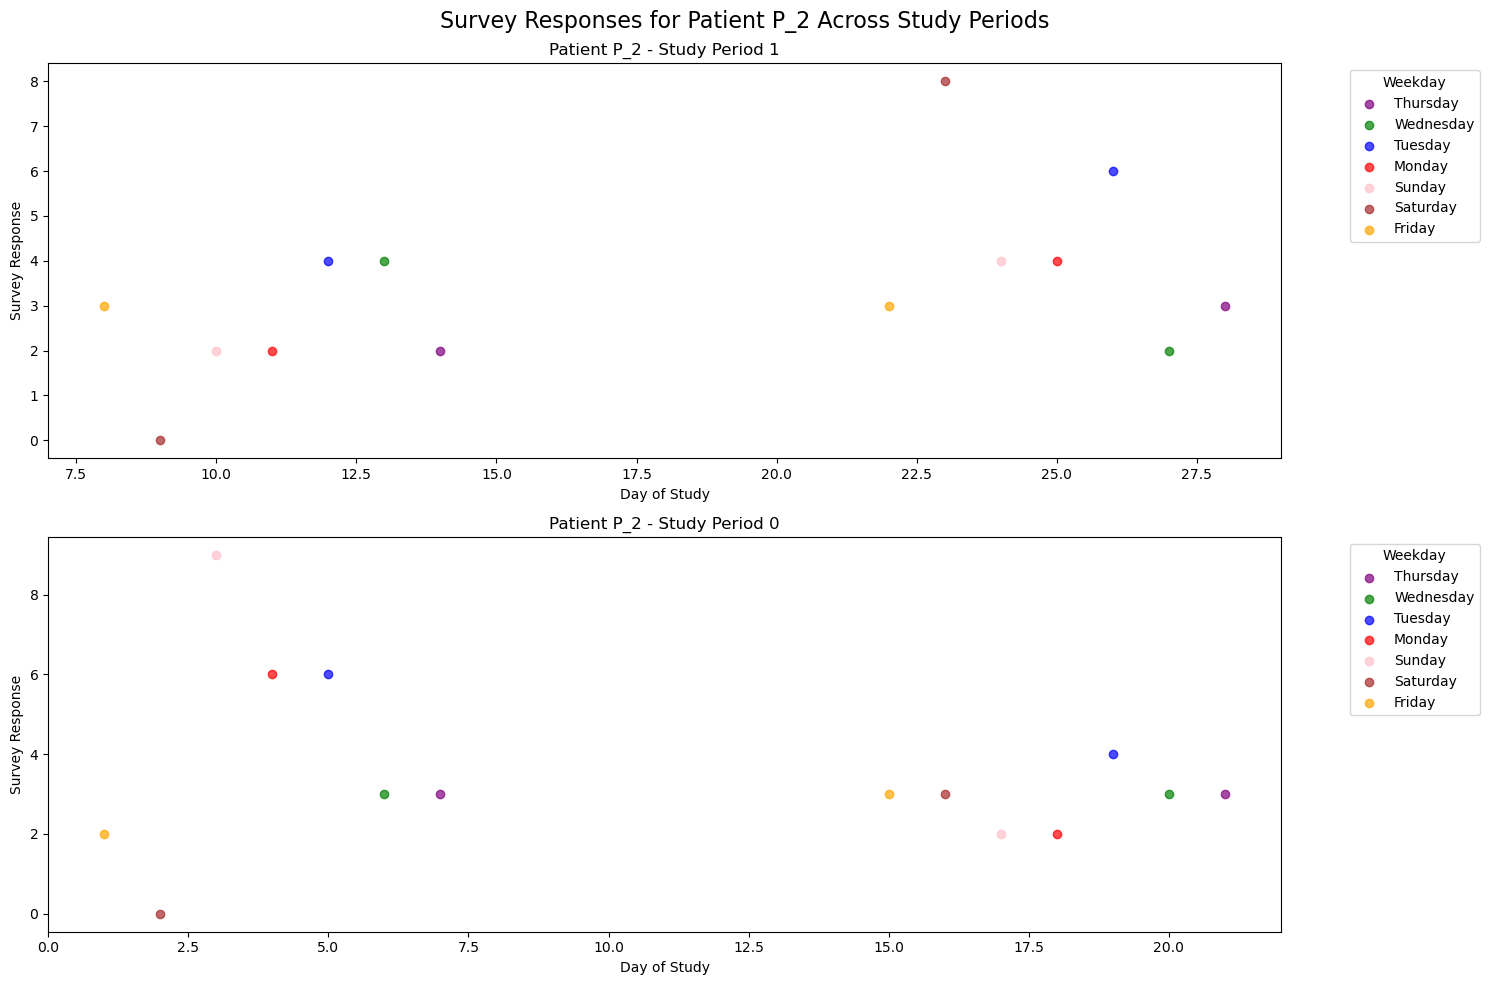


Example Patient: P_2

Patient Data Summary:
     current_day_of_study    weekday  current_period_of_study  survey1_question1_response
250                    28   Thursday                        4                           3
272                    27  Wednesday                        4                           2
289                    26    Tuesday                        4                           6
300                    25     Monday                        4                           4
315                    24     Sunday                        4                           4
345                    23   Saturday                        4                           8
363                    22     Friday                        4                           3
375                    21   Thursday                        3                           3
403                    20  Wednesday                        3                           3
416                    19    Tuesday                   

In [10]:
# Detailed Patient Data Exploration
# Select a single patient
example_patient = df['manuscript_ID'].mode().values[0]
patient_data = df[df['manuscript_ID'] == example_patient].copy()

# Create a figure with subplots for different study periods
plt.figure(figsize=(15, 10))

# Get unique study periods for this patient
study_periods = patient_data['intervention_period'].unique()

# Color palette for weekdays
weekday_colors = {
    'Monday': 'red', 
    'Tuesday': 'blue', 
    'Wednesday': 'green', 
    'Thursday': 'purple', 
    'Friday': 'orange', 
    'Saturday': 'brown', 
    'Sunday': 'pink'
}

# Plot for each study period
for i, period in enumerate(study_periods, 1):
    plt.subplot(len(study_periods), 1, i)
    
    # Filter data for current period
    period_data = patient_data[patient_data['intervention_period'] == period]
    
    # Scatter plot with weekday colors
    for weekday in period_data['weekday'].unique():
        weekday_data = period_data[period_data['weekday'] == weekday]
        plt.scatter(
            weekday_data['current_day_of_study'], 
            weekday_data['survey1_question1_response'], 
            label=weekday, 
            color=weekday_colors.get(weekday, 'gray'),
            alpha=0.7
        )
    
    plt.title(f'Patient {example_patient} - Study Period {period}')
    plt.xlabel('Day of Study')
    plt.ylabel('Survey Response')
    plt.legend(title='Weekday', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()

plt.suptitle(f'Survey Responses for Patient {example_patient} Across Study Periods', fontsize=16)
plt.tight_layout()
plt.show()

# Print some additional context about the patient
print(f"\nExample Patient: {example_patient}")
print("\nPatient Data Summary:")
print(patient_data[['current_day_of_study', 'weekday', 'current_period_of_study', 'survey1_question1_response']].to_string())

In [11]:
df_clean
all_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Convert the column to a Categorical type with ALL levels defined
df_clean['weekday'] = pd.Categorical(df_clean['weekday'], categories=all_days)
df_clean

,manuscript_ID,current_day_of_study,survey1_question1_response,survey1_question2_response,survey1_question3_response,weekday,intervention_period,current_period_of_study,sequence,current_day_of_study_harmonized,dem_sex_birth,stress_group,manuscript_encoded,period_encoded,weekday_encoded
0,P_76,18,1,1,[ja],Thursday,1,3,ABAB,18,women,low_stress,40,1,3
1,P_76,17,2,2,[ja],Wednesday,1,3,ABAB,17,women,low_stress,40,1,2
2,P_76,16,0,2,[ja],Tuesday,1,3,ABAB,16,women,low_stress,40,1,1
3,P_76,15,0,0,[ja],Monday,1,3,ABAB,15,women,low_stress,40,1,0
4,P_76,14,0,1,[nein],Sunday,0,2,ABAB,14,women,low_stress,40,0,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
657,P_4,3,4,4,[nein],Thursday,0,1,BABA,4,women,high_stress,16,0,3
658,P_4,2,7,5,[nein],Wednesday,0,1,BABA,3,women,high_stress,16,0,2
659,P_3,2,2,2,[nein],Wednesday,0,1,BABA,3,men,low_stress,11,0,2
660,P_4,1,5,7,[nein],Tuesday,0,1,BABA,2,women,high_stress,16,0,1


In [12]:
# Fit individual linear regression models for each patient
# with weekday as a categorical variable

from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Dictionary to store models and results for each patient
patient_models = {}
patient_results = {}
patient_summaries = {}

# Get unique patients
patients = df_clean['manuscript_ID'].unique()

print(f"Fitting linear regression models for {len(patients)} patients...\n")

# Fit a model for each patient
for patient_id in patients:
    patient_data = df_clean[df_clean['manuscript_ID'] == patient_id].copy()
    
    # Skip patients with insufficient data
    if len(patient_data) < 5:
        continue
    
    try:
        # Fit linear regression with weekday as categorical variable and intervention_period as covariate
        # Formula: response ~ C(weekday) + intervention_period where C() specifies categorical
        model = smf.ols('survey1_question1_response ~ C(weekday, Treatment(reference="Monday")) + intervention_period', data=patient_data).fit()
        
        patient_models[patient_id] = model
        
        # Store predictions and residuals
        patient_data['predicted'] = model.predict(patient_data)
        patient_data['residuals'] = model.resid
        
        patient_results[patient_id] = patient_data
        patient_summaries[patient_id] = {
            'n_observations': len(patient_data),
            'r_squared': model.rsquared,
            'adjusted_r_squared': model.rsquared_adj,
            'rmse': numpy.sqrt(model.mse_resid),
            'aic': model.aic,
            'bic': model.bic
        }
    except Exception as e:
        print(f"Error fitting model for patient {patient_id}: {str(e)}")
        continue

print(f"Successfully fitted {len(patient_models)} patient-level models\n")

# Display summary statistics for all models
print("Summary of Patient-Level Model Performance:")
print("-" * 80)
summary_df = pandas.DataFrame(patient_summaries).T
print(summary_df.to_string())


Fitting linear regression models for 43 patients...

Successfully fitted 35 patient-level models

Summary of Patient-Level Model Performance:
--------------------------------------------------------------------------------
      n_observations  r_squared  adjusted_r_squared      rmse         aic         bic
P_76            16.0   0.522776            0.105204  2.278117   76.662846   82.843556
P_75            21.0   0.375067            0.038564  1.805471   90.338889   98.695069
P_74            27.0   0.516284            0.338073  1.360147   99.744950  110.111645
P_72            18.0   0.478472            0.113403  1.425153   69.255673   76.378647
P_68            26.0   0.201129           -0.109543  1.764525  109.753793  119.818565
P_66            18.0   0.229401           -0.310019  1.234534   64.086594   71.209568
P_65            25.0   0.441171            0.211065  1.349978   92.309772  102.060779
P_62            23.0   0.192465           -0.184385  2.119931  106.003605  115.087558
P_6

/opt/homebrew/anaconda3/envs/adaptive_nof1/lib/python3.13/site-packages/statsmodels/regression/linear_model.py:1795: RuntimeWarning: divide by zero encountered in divide
  return 1 - (np.divide(self.nobs - self.k_constant, self.df_resid)
/opt/homebrew/anaconda3/envs/adaptive_nof1/lib/python3.13/site-packages/statsmodels/regression/linear_model.py:1795: RuntimeWarning: invalid value encountered in scalar multiply
  return 1 - (np.divide(self.nobs - self.k_constant, self.df_resid)
/opt/homebrew/anaconda3/envs/adaptive_nof1/lib/python3.13/site-packages/statsmodels/regression/linear_model.py:1795: RuntimeWarning: divide by zero encountered in divide
  return 1 - (np.divide(self.nobs - self.k_constant, self.df_resid)
/opt/homebrew/anaconda3/envs/adaptive_nof1/lib/python3.13/site-packages/statsmodels/regression/linear_model.py:1795: RuntimeWarning: invalid value encountered in scalar multiply
  return 1 - (np.divide(self.nobs - self.k_constant, self.df_resid)
/opt/homebrew/anaconda3/envs/ada

In [13]:
# Detailed results for a sample of patients
sample_patients = list(patient_models.keys())[:5]  # First 5 patients

for patient_id in sample_patients:
    print(f"\n{'='*80}")
    print(f"PATIENT: {patient_id}")
    print(f"{'='*80}")
    
    model = patient_models[patient_id]
    print(model.summary())
    
    print(f"\nModel Performance Metrics:")
    for key, value in patient_summaries[patient_id].items():
        print(f"  {key}: {value:.4f}")



PATIENT: P_76
                                OLS Regression Results                                
Dep. Variable:     survey1_question1_response   R-squared:                       0.523
Model:                                    OLS   Adj. R-squared:                  0.105
Method:                         Least Squares   F-statistic:                     1.252
Date:                        Thu, 08 Jan 2026   Prob (F-statistic):              0.377
Time:                                13:45:02   Log-Likelihood:                -30.331
No. Observations:                          16   AIC:                             76.66
Df Residuals:                               8   BIC:                             82.84
Df Model:                                   7                                         
Covariance Type:                    nonrobust                                         
                                                             coef    std err          t      P>|t|      [0.025     

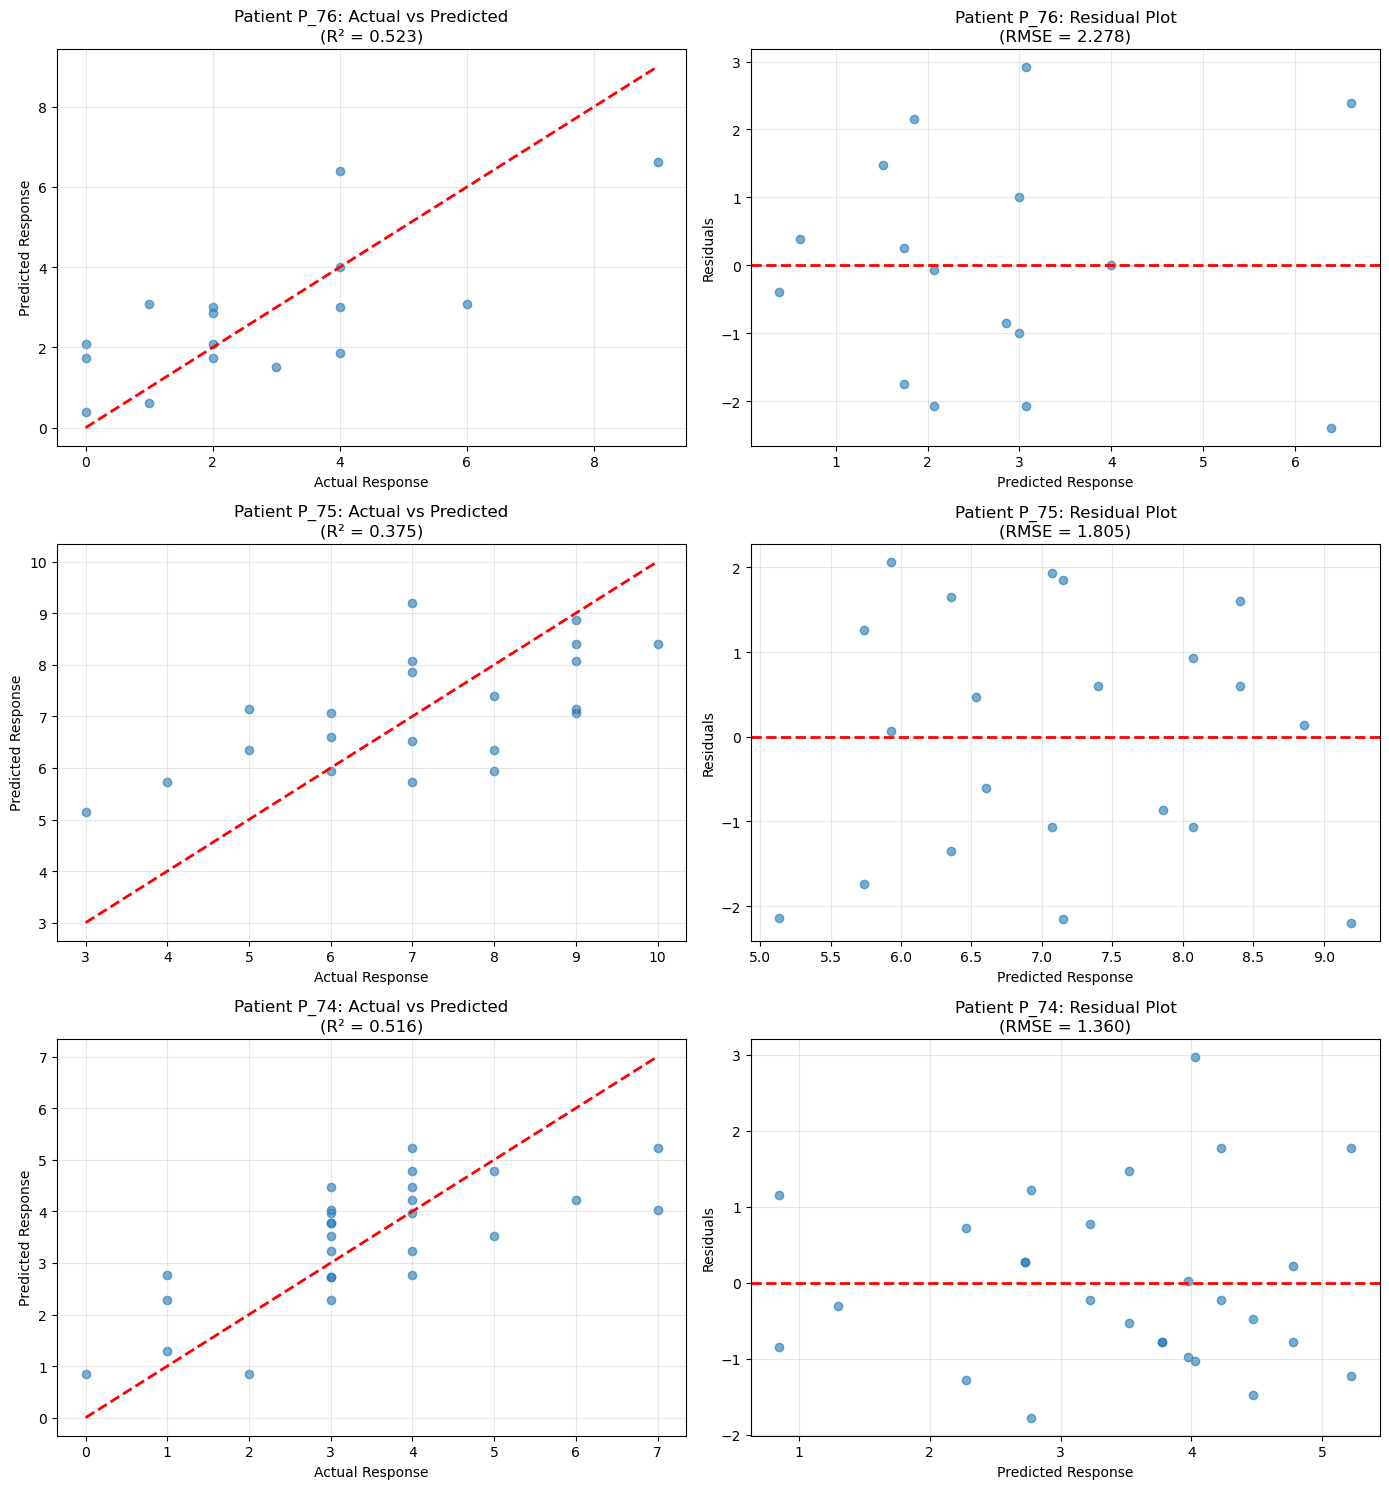

In [14]:
# Visualization of fitted models for sample patients
sample_patients = list(patient_models.keys())[:3]  # First 3 patients

fig, axes = plt.subplots(len(sample_patients), 2, figsize=(14, 5*len(sample_patients)))

if len(sample_patients) == 1:
    axes = axes.reshape(1, -1)

for idx, patient_id in enumerate(sample_patients):
    patient_data = patient_results[patient_id]
    
    # Plot 1: Actual vs Predicted
    ax1 = axes[idx, 0]
    ax1.scatter(patient_data['survey1_question1_response'], 
                patient_data['predicted'], alpha=0.6)
    ax1.plot([patient_data['survey1_question1_response'].min(), 
              patient_data['survey1_question1_response'].max()], 
             [patient_data['survey1_question1_response'].min(), 
              patient_data['survey1_question1_response'].max()], 'r--', lw=2)
    ax1.set_xlabel('Actual Response')
    ax1.set_ylabel('Predicted Response')
    ax1.set_title(f'Patient {patient_id}: Actual vs Predicted\n(R² = {patient_summaries[patient_id]["r_squared"]:.3f})')
    ax1.grid(True, alpha=0.3)
    
    # Plot 2: Residuals
    ax2 = axes[idx, 1]
    ax2.scatter(patient_data['predicted'], patient_data['residuals'], alpha=0.6)
    ax2.axhline(y=0, color='r', linestyle='--', lw=2)
    ax2.set_xlabel('Predicted Response')
    ax2.set_ylabel('Residuals')
    ax2.set_title(f'Patient {patient_id}: Residual Plot\n(RMSE = {patient_summaries[patient_id]["rmse"]:.3f})')
    ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [15]:
# Extract and analyze coefficients from all patient models

# Dictionary to store coefficients for each patient
all_coefficients = {}

for patient_id, model in patient_models.items():
    coefficients = model.params.to_dict()
    all_coefficients[patient_id] = coefficients

# Convert to DataFrame for easier analysis
coefficients_df = pandas.DataFrame(all_coefficients).T

print("Coefficient Summary Statistics:")
print("=" * 80)
print(coefficients_df.describe().to_string())

# Calculate mean and std for each coefficient
print("\n" + "=" * 80)
print("Mean and Standard Deviation of Coefficients:")
print("=" * 80)
coef_stats = pandas.DataFrame({
    'Mean': coefficients_df.mean(),
    'Std': coefficients_df.std(),
    'Min': coefficients_df.min(),
    'Max': coefficients_df.max()
})
print(coef_stats.to_string())


Coefficient Summary Statistics:
       Intercept  C(weekday, Treatment(reference="Monday"))[T.Tuesday]  C(weekday, Treatment(reference="Monday"))[T.Wednesday]  C(weekday, Treatment(reference="Monday"))[T.Thursday]  C(weekday, Treatment(reference="Monday"))[T.Friday]  C(weekday, Treatment(reference="Monday"))[T.Saturday]  C(weekday, Treatment(reference="Monday"))[T.Sunday]  intervention_period
count  35.000000                                             35.000000                                               35.000000                                              35.000000                                            35.000000                                           3.500000e+01                                            35.000000            35.000000
mean    3.775749                                              0.814028                                                0.632641                                               0.310619                                             0.571706      

In [16]:
# Find manuscript_ids with high and low intervention_period coefficients
intervention_coeffs = coefficients_df['intervention_period'].sort_values()

print("Manuscript IDs with lowest intervention_period coefficients:")
print("=" * 80)
print(intervention_coeffs.head())

print("\n" + "=" * 80)
print("Manuscript IDs with highest intervention_period coefficients:")
print("=" * 80)
print(intervention_coeffs.tail())

# Find one close to zero
abs_coeffs = coefficients_df['intervention_period'].abs().sort_values()
print("\n" + "=" * 80)
print("Manuscript IDs with intervention_period coefficients closest to zero:")
print("=" * 80)
print(coefficients_df.loc[abs_coeffs.head(10).index, 'intervention_period'])

# Examples
high_example = intervention_coeffs.idxmax()
zero_example = abs_coeffs.idxmin()

print("\n" + "=" * 80)
print(f"HIGH intervention_period coefficient example: {high_example}")
print(f"  Coefficient value: {coefficients_df.loc[high_example, 'intervention_period']:.4f}")

print(f"\nZERO (closest to 0) intervention_period coefficient example: {zero_example}")
print(f"  Coefficient value: {coefficients_df.loc[zero_example, 'intervention_period']:.4f}")

Manuscript IDs with lowest intervention_period coefficients:
P_16   -2.588235
P_56   -1.600000
P_12   -1.473684
P_36   -1.375000
P_51   -1.333333
Name: intervention_period, dtype: float64

Manuscript IDs with highest intervention_period coefficients:
P_21    1.875000
P_9     2.428571
P_8     2.631579
P_34    3.333333
P_10    5.000000
Name: intervention_period, dtype: float64

Manuscript IDs with intervention_period coefficients closest to zero:
P_62   -0.030303
P_26   -0.033333
P_66    0.055556
P_68    0.078947
P_2    -0.142857
P_76    0.222222
P_6     0.250000
P_67    0.315789
P_40   -0.375000
P_61    0.380952
Name: intervention_period, dtype: float64

HIGH intervention_period coefficient example: P_10
  Coefficient value: 5.0000

ZERO (closest to 0) intervention_period coefficient example: P_62
  Coefficient value: -0.0303


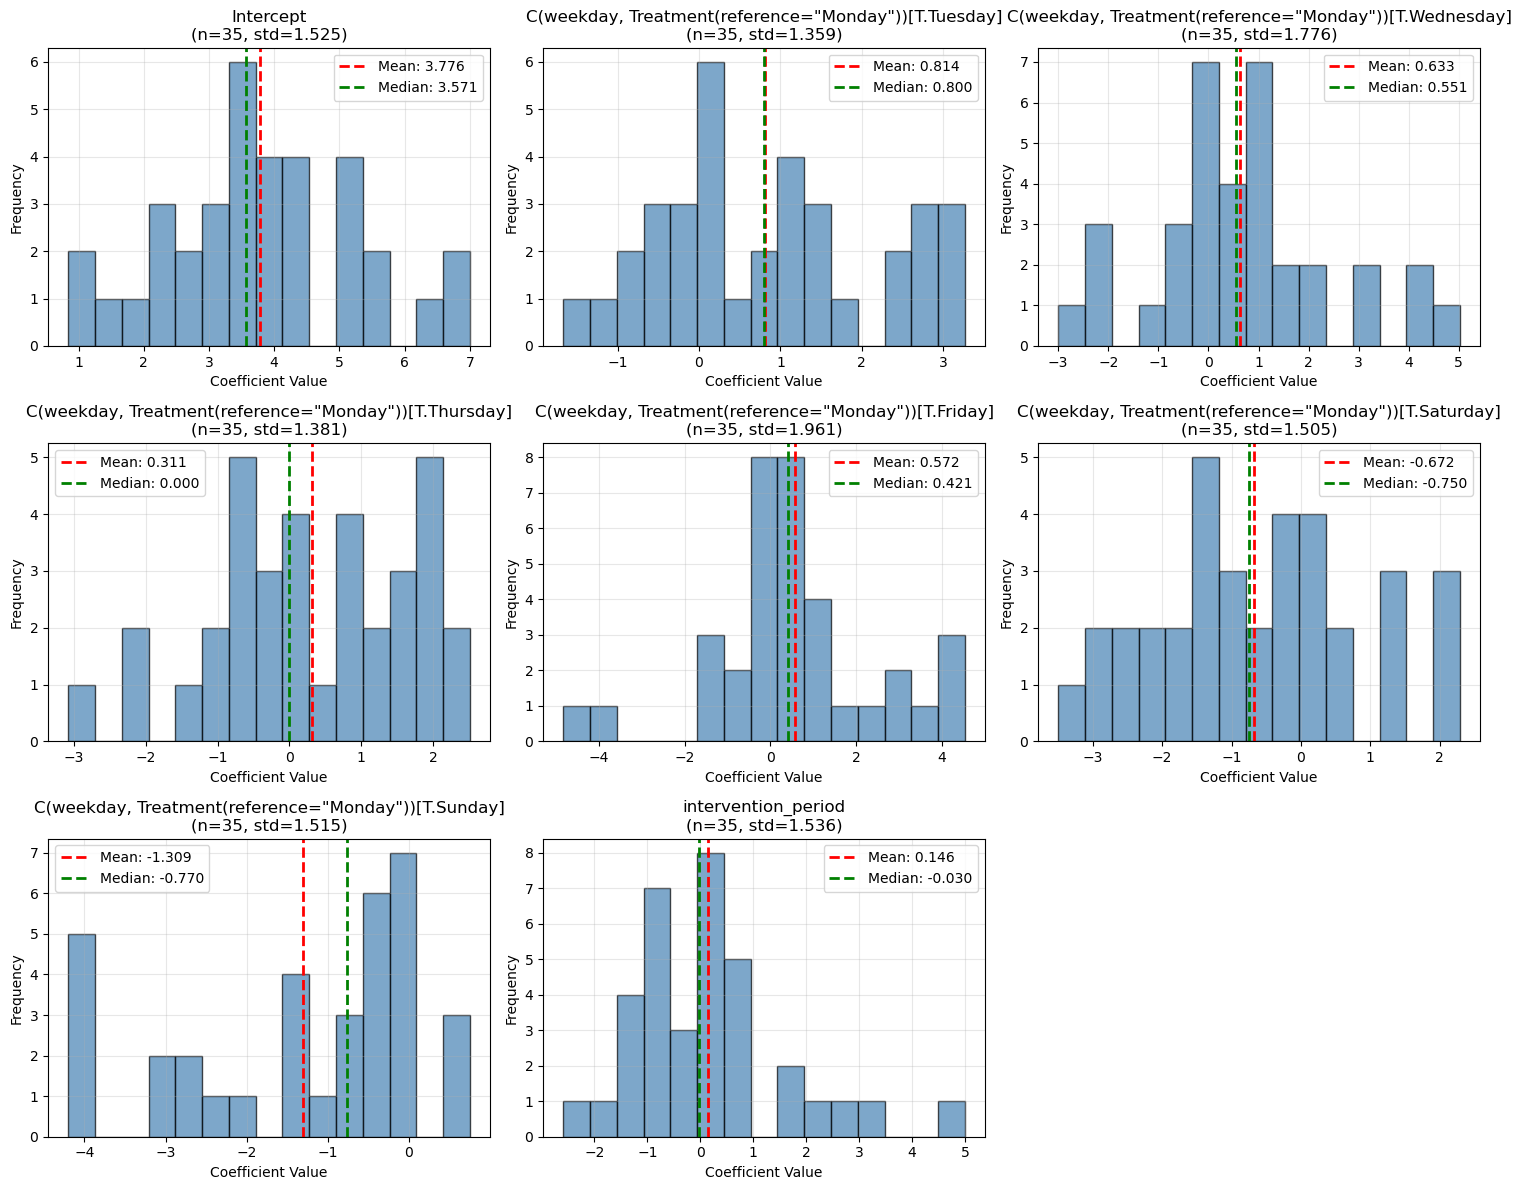

In [17]:
# Visualize distribution of coefficients

# Get column names (which are the coefficients/terms)
coefficient_names = coefficients_df.columns.tolist()

# Create subplots for each coefficient
n_coefs = len(coefficient_names)
n_cols = 3
n_rows = (n_coefs + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows))
axes = axes.flatten()

for idx, coef_name in enumerate(coefficient_names):
    ax = axes[idx]
    
    # Get values for this coefficient across all patients
    coef_values = coefficients_df[coef_name].dropna()
    
    # Plot histogram
    ax.hist(coef_values, bins=15, edgecolor='black', alpha=0.7, color='steelblue')
    ax.axvline(coef_values.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {coef_values.mean():.3f}')
    ax.axvline(coef_values.median(), color='green', linestyle='--', linewidth=2, label=f'Median: {coef_values.median():.3f}')
    
    ax.set_xlabel('Coefficient Value')
    ax.set_ylabel('Frequency')
    ax.set_title(f'{coef_name}\n(n={len(coef_values)}, std={coef_values.std():.3f})')
    ax.legend()
    ax.grid(True, alpha=0.3)

# Hide unused subplots
for idx in range(n_coefs, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()


/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_81721/3233787105.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(box_data, labels=coefficients_df.columns, patch_artist=True)


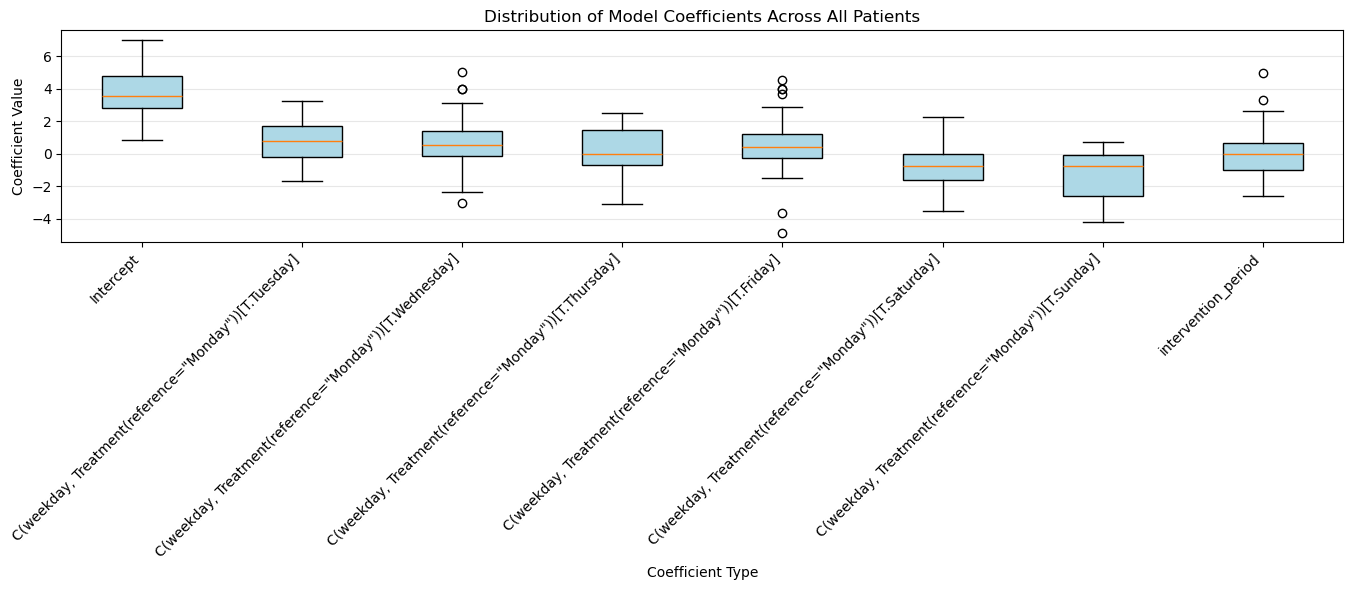


Detailed Coefficient Statistics by Type:

Intercept:
  Count:     35
  Mean:      3.775749
  Std Dev:   1.524925
  Median:    3.571429
  Min:       0.842105
  Max:       7.000000
  IQR:       1.924242

C(weekday, Treatment(reference="Monday"))[T.Tuesday]:
  Count:     35
  Mean:      0.814028
  Std Dev:   1.358652
  Median:    0.800000
  Min:       -1.666667
  Max:       3.264368
  IQR:       1.865741

C(weekday, Treatment(reference="Monday"))[T.Wednesday]:
  Count:     35
  Mean:      0.632641
  Std Dev:   1.775505
  Median:    0.550926
  Min:       -3.000000
  Max:       5.021739
  IQR:       1.514683

C(weekday, Treatment(reference="Monday"))[T.Thursday]:
  Count:     35
  Mean:      0.310619
  Std Dev:   1.381397
  Median:    0.000000
  Min:       -3.083333
  Max:       2.515152
  IQR:       2.167723

C(weekday, Treatment(reference="Monday"))[T.Friday]:
  Count:     35
  Mean:      0.571706
  Std Dev:   1.960578
  Median:    0.420635
  Min:       -4.833333
  Max:       4.537037
  

In [18]:
# Box plot comparison of all coefficients

fig, ax = plt.subplots(figsize=(14, 6))

# Prepare data for box plot
box_data = [coefficients_df[col].dropna().values for col in coefficients_df.columns]

bp = ax.boxplot(box_data, labels=coefficients_df.columns, patch_artist=True)

# Color the boxes
for patch in bp['boxes']:
    patch.set_facecolor('lightblue')

ax.set_xlabel('Coefficient Type')
ax.set_ylabel('Coefficient Value')
ax.set_title('Distribution of Model Coefficients Across All Patients')
ax.grid(True, alpha=0.3, axis='y')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Print detailed statistics
print("\nDetailed Coefficient Statistics by Type:")
print("=" * 80)
for col in coefficients_df.columns:
    values = coefficients_df[col].dropna()
    print(f"\n{col}:")
    print(f"  Count:     {len(values)}")
    print(f"  Mean:      {values.mean():.6f}")
    print(f"  Std Dev:   {values.std():.6f}")
    print(f"  Median:    {values.median():.6f}")
    print(f"  Min:       {values.min():.6f}")
    print(f"  Max:       {values.max():.6f}")
    print(f"  IQR:       {values.quantile(0.75) - values.quantile(0.25):.6f}")


In [19]:
# Potential informative priors:
# stds: 1.5
# Monday: 3.7
# Tuesday - Thursday: .5
# Saturday: -0.5
# Sunday: -1.0

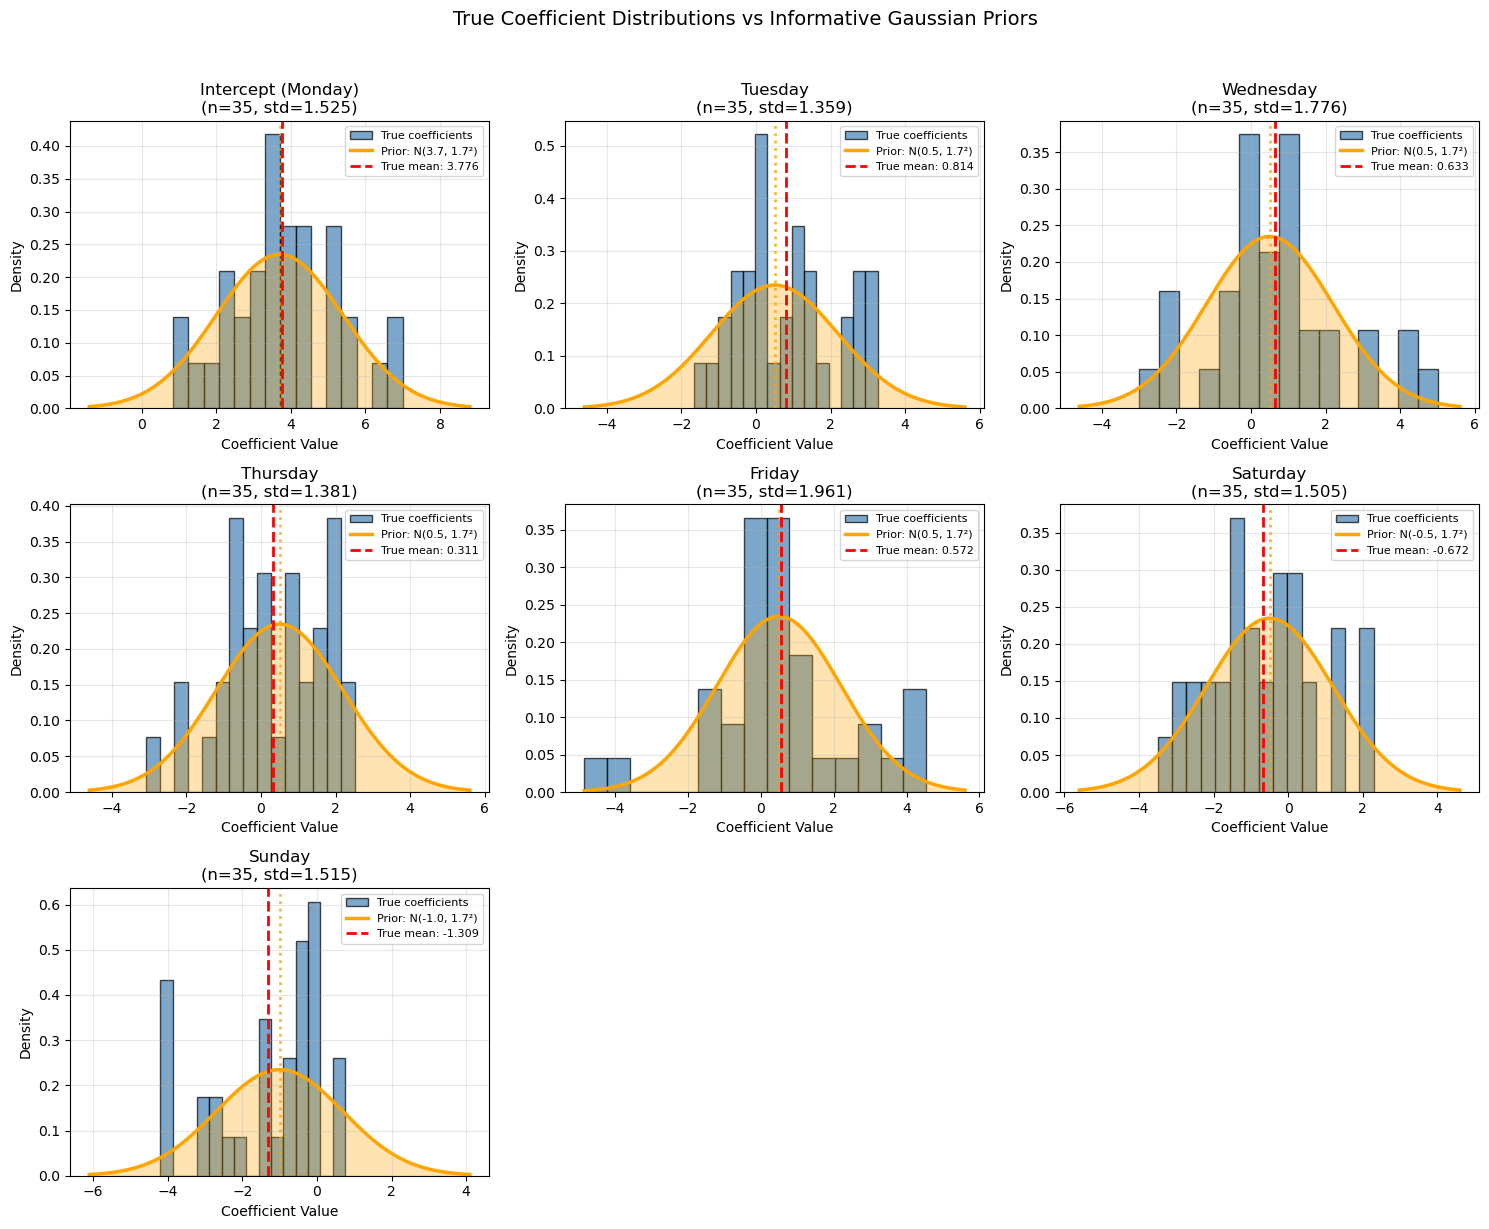


Comparison of True Coefficient Statistics vs Prior Means:
       Coefficient  True Mean  True Std  Prior Mean  Prior Std  Difference
Intercept (Monday)   3.775749  1.524925         3.7        1.7   -0.075749
           Tuesday   0.814028  1.358652         0.5        1.7   -0.314028
         Wednesday   0.632641  1.775505         0.5        1.7   -0.132641
          Thursday   0.310619  1.381397         0.5        1.7    0.189381
            Friday   0.571706  1.960578         0.5        1.7   -0.071706
          Saturday  -0.672304  1.505317        -0.5        1.7    0.172304
            Sunday  -1.309168  1.514692        -1.0        1.7    0.309168

Note: Prior distributions are Gaussian with std = 1.7


In [20]:
# Plot true coefficient distributions with informative Gaussian priors overlaid
import numpy as np
from scipy.stats import norm

# Map coefficient names from coefficients_df to weekday names and prior means
# Proposed informative priors (from cell 21)
prior_means_map = {
    'Intercept': 3.7,  # Monday baseline
    'C(weekday, Treatment(reference="Monday"))[T.Tuesday]': 0.5,
    'C(weekday, Treatment(reference="Monday"))[T.Wednesday]': 0.5,
    'C(weekday, Treatment(reference="Monday"))[T.Thursday]': 0.5,
    'C(weekday, Treatment(reference="Monday"))[T.Friday]': 0.5,  # Not specified, using 0.5
    'C(weekday, Treatment(reference="Monday"))[T.Saturday]': -0.5,
    'C(weekday, Treatment(reference="Monday"))[T.Sunday]': -1.0
}

# Short names for display
short_names = {
    'Intercept': 'Intercept (Monday)',
    'C(weekday, Treatment(reference="Monday"))[T.Tuesday]': 'Tuesday',
    'C(weekday, Treatment(reference="Monday"))[T.Wednesday]': 'Wednesday',
    'C(weekday, Treatment(reference="Monday"))[T.Thursday]': 'Thursday',
    'C(weekday, Treatment(reference="Monday"))[T.Friday]': 'Friday',
    'C(weekday, Treatment(reference="Monday"))[T.Saturday]': 'Saturday',
    'C(weekday, Treatment(reference="Monday"))[T.Sunday]': 'Sunday'
}

prior_std = 1.7

# Filter to only weekday coefficients (exclude intervention_period)
weekday_coefs = [col for col in coefficients_df.columns if col in prior_means_map]

# Create figure with subplots
n_coefs = len(weekday_coefs)
n_cols = 3
n_rows = (n_coefs + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows))
axes = axes.flatten()

# Colors
true_color = 'steelblue'
prior_color = 'orange'

# Plot each coefficient
for idx, coef_name in enumerate(weekday_coefs):
    ax = axes[idx]
    
    # Get true coefficient values from the data
    coef_values = coefficients_df[coef_name].dropna()
    
    # Plot histogram of true coefficients
    n, bins, patches = ax.hist(coef_values, bins=15, edgecolor='black', alpha=0.7, 
                               color=true_color, density=True, label='True coefficients')
    
    # Overlay Gaussian prior
    prior_mean = prior_means_map[coef_name]
    x_min = min(coef_values.min(), prior_mean - 3 * prior_std)
    x_max = max(coef_values.max(), prior_mean + 3 * prior_std)
    x = np.linspace(x_min, x_max, 1000)
    
    prior_pdf = norm.pdf(x, loc=prior_mean, scale=prior_std)
    ax.plot(x, prior_pdf, color=prior_color, linewidth=2.5, 
            label=f'Prior: N({prior_mean:.1f}, {prior_std:.1f}²)')
    
    # Shade the prior distribution
    ax.fill_between(x, prior_pdf, alpha=0.3, color=prior_color)
    
    # Mark the prior mean and true mean
    ax.axvline(prior_mean, color=prior_color, linestyle=':', linewidth=2, alpha=0.8)
    ax.axvline(coef_values.mean(), color='red', linestyle='--', linewidth=2, 
               label=f'True mean: {coef_values.mean():.3f}')
    
    ax.set_xlabel('Coefficient Value')
    ax.set_ylabel('Density')
    ax.set_title(f'{short_names[coef_name]}\n(n={len(coef_values)}, std={coef_values.std():.3f})')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

# Hide unused subplots
for idx in range(n_coefs, len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('True Coefficient Distributions vs Informative Gaussian Priors', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Print comparison table
print("\nComparison of True Coefficient Statistics vs Prior Means:")
print("=" * 80)
comparison_data = []
for coef_name in weekday_coefs:
    coef_values = coefficients_df[coef_name].dropna()
    comparison_data.append({
        'Coefficient': short_names[coef_name],
        'True Mean': coef_values.mean(),
        'True Std': coef_values.std(),
        'Prior Mean': prior_means_map[coef_name],
        'Prior Std': prior_std,
        'Difference': prior_means_map[coef_name] - coef_values.mean()
    })

comparison_df = pandas.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))
print("\nNote: Prior distributions are Gaussian with std =", prior_std)


In [21]:
# Fit NIG conjugate model with informative priors
from adaptive_nof1.inference.bayesian_linear_regression import NIGLinearRegression
import numpy as np

# Prepare data for fitting
# Use the cleaned dataframe and create design matrix with weekday dummies (Monday as reference)
df_model = df_clean.copy()

# Create weekday dummies with Monday as reference (drop Monday)
# Ensure consistent order: Tuesday, Wednesday, Thursday, Friday, Saturday, Sunday
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df_model['weekday'] = pd.Categorical(df_model['weekday'], categories=weekday_order, ordered=True)

weekday_dummies = pd.get_dummies(df_model['weekday'], prefix='weekday', drop_first=False)
# Remove Monday column to use it as reference
if 'weekday_Monday' in weekday_dummies.columns:
    weekday_dummies = weekday_dummies.drop('weekday_Monday', axis=1)

# Ensure columns are in the correct order: Tuesday through Sunday
expected_cols = ['weekday_Tuesday', 'weekday_Wednesday', 'weekday_Thursday', 
                 'weekday_Friday', 'weekday_Saturday', 'weekday_Sunday']
weekday_dummies = weekday_dummies[expected_cols]

# Design matrix: intercept + weekday dummies
X = np.hstack([np.ones((len(df_model), 1)), weekday_dummies.values])
y = df_model['survey1_question1_response'].values

print(f"Design matrix shape: {X.shape}")
print(f"Number of observations: {len(y)}")
print(f"\nWeekday columns in design matrix (in order):")
print([col for col in weekday_dummies.columns])

# Set up informative priors
# Prior means: [Intercept (Monday), Tuesday, Wednesday, Thursday, Friday, Saturday, Sunday]
prior_means = np.array([
    3.7,   # Intercept (Monday baseline)
    0.5,   # Tuesday
    0.5,   # Wednesday
    0.5,   # Thursday
    0.5,   # Friday
    -0.5,  # Saturday
    -1.0   # Sunday
])

# Prior covariance matrix: 
# In NIG model, β ~ N(μ, σ²V), so the marginal variance is σ² * V
# We want the marginal prior std to be around 1.5-2.0 (matching the true coefficient stds)
# The posterior covariance v* gets updated as: v* = inv(inv(V) + X'X)
# With lots of data, this can become very small, so we need V to be large enough
# Setting V to a much larger value to ensure posterior uncertainty is reasonable
# Using V = 10.0 (diagonal) to give sufficient prior uncertainty
prior_cov_diag = 10.0  # Diagonal value for V matrix - increased significantly
prior_cov = np.eye(len(prior_means)) * prior_cov_diag

# Inverse-gamma prior for variance (1/sigma^2 ~ Gamma(a, b))
# Use priors that give reasonable expected variance
# E[σ²] = b / (a - 1) for a > 1
# Let's set a=2, b=4 so E[σ²] = 4
prior_a = 2.0
prior_b = 4.0

# Calculate effective prior std (marginal, accounting for σ²)
# Marginal variance ≈ E[σ²] * V, so marginal std ≈ sqrt(E[σ²] * V)
expected_sigma2 = prior_b / (prior_a - 1) if prior_a > 1 else prior_b
effective_prior_std = np.sqrt(expected_sigma2 * prior_cov_diag)

print(f"\nPrior parameters:")
print(f"  Prior means: {prior_means}")
print(f"  Prior covariance V (diagonal): {np.diag(prior_cov)}")
print(f"  Expected σ²: {expected_sigma2:.2f}")
print(f"  Effective marginal prior std: {effective_prior_std:.2f}")
print(f"  Inverse-gamma: a={prior_a}, b={prior_b}")

# Initialize and fit the NIG model
nig_model = NIGLinearRegression(
    mu=prior_means,
    v=prior_cov,
    a=prior_a,
    b=prior_b
)

# Fit the model
nig_model.fit(X, y)

# Extract posterior parameters
posterior_means = nig_model.mu
posterior_cov = nig_model.v
posterior_a = nig_model.a
posterior_b = nig_model.b

print(f"\nPosterior parameters:")
print(f"  Posterior means: {posterior_means}")
print(f"  Posterior stds (sqrt of diagonal): {np.sqrt(np.diag(posterior_cov))}")
print(f"  Inverse-gamma: a={posterior_a:.2f}, b={posterior_b:.2f}")

# Calculate posterior variance of error term
# E[sigma^2] = b / (a - 1) for a > 1
if posterior_a > 1:
    posterior_error_variance = posterior_b / (posterior_a - 1)
    print(f"  Posterior error variance: {posterior_error_variance:.4f}")
    print(f"  Posterior error std: {np.sqrt(posterior_error_variance):.4f}")

# Compare prior vs posterior means
print(f"\nComparison of Prior vs Posterior Means:")
print("=" * 80)
coef_names = ['Intercept (Monday)', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
comparison = pd.DataFrame({
    'Coefficient': coef_names,
    'Prior Mean': prior_means,
    'Posterior Mean': posterior_means,
    'Difference': posterior_means - prior_means,
    'Posterior Std': np.sqrt(np.diag(posterior_cov))
})
print(comparison.to_string(index=False))


Design matrix shape: (662, 7)
Number of observations: 662

Weekday columns in design matrix (in order):
['weekday_Tuesday', 'weekday_Wednesday', 'weekday_Thursday', 'weekday_Friday', 'weekday_Saturday', 'weekday_Sunday']

Prior parameters:
  Prior means: [ 3.7  0.5  0.5  0.5  0.5 -0.5 -1. ]
  Prior covariance V (diagonal): [10. 10. 10. 10. 10. 10. 10.]
  Expected σ²: 4.00
  Effective marginal prior std: 6.32
  Inverse-gamma: a=2.0, b=4.0

Posterior parameters:
  Posterior means: [ 4.02804992  0.68051269  0.60105002  0.05160196  0.40387749 -1.09633
 -1.20174368]
  Posterior stds (sqrt of diagonal): [0.09867705 0.13934705 0.14470197 0.14003251 0.14514064 0.14558801
 0.14343566]
  Inverse-gamma: a=333.00, b=1379.39
  Posterior error variance: 4.1548
  Posterior error std: 2.0383

Comparison of Prior vs Posterior Means:
       Coefficient  Prior Mean  Posterior Mean  Difference  Posterior Std
Intercept (Monday)         3.7        4.028050    0.328050       0.098677
           Tuesday      

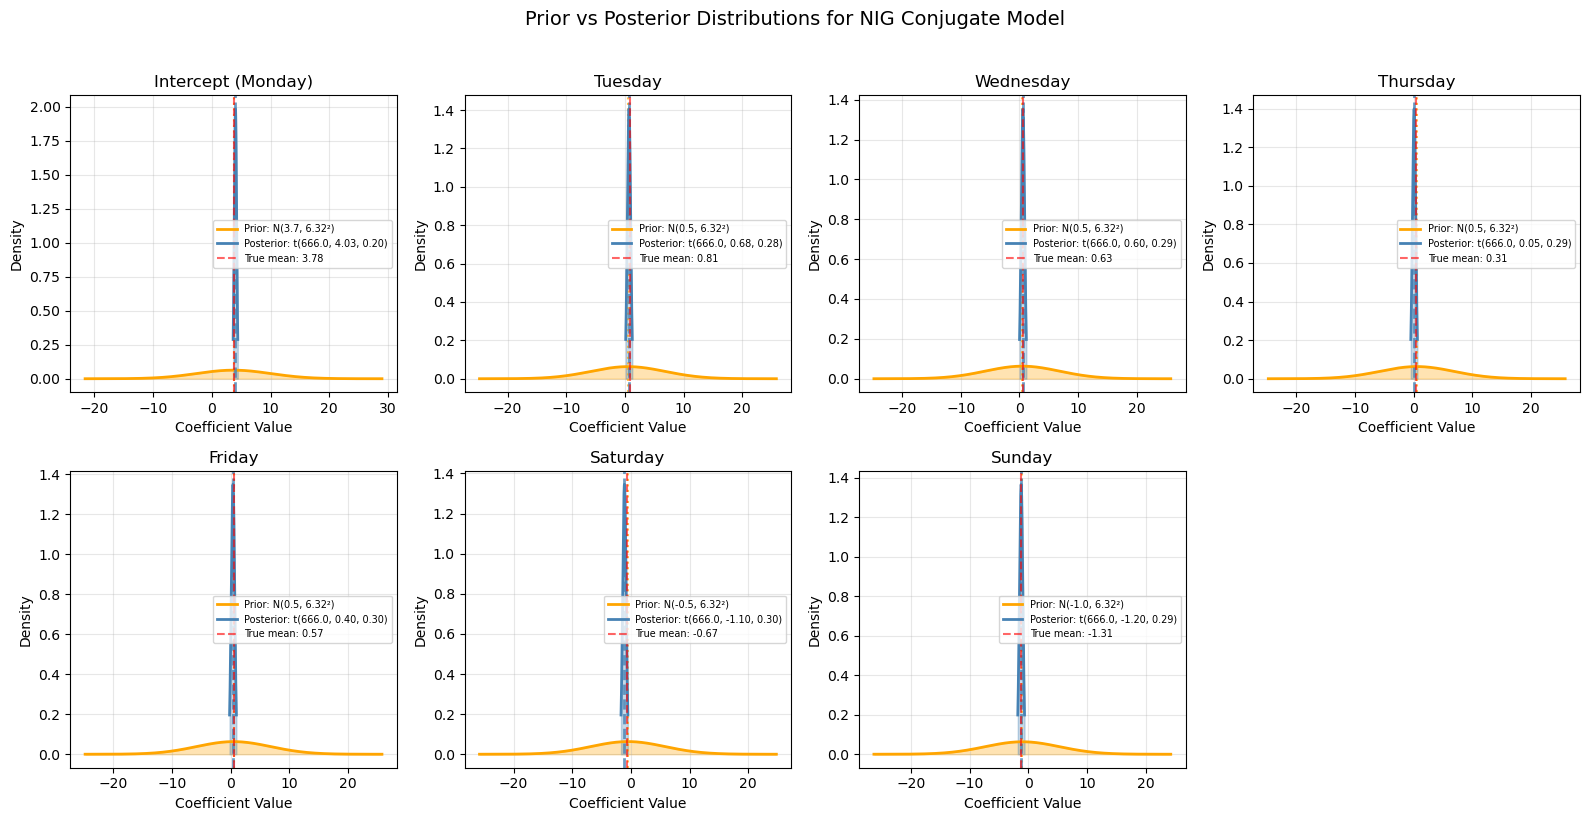


Summary Statistics:
Number of observations: 662
Prior error variance (E[σ²]): 4.0000
Posterior error variance (E[σ²]): 4.1548

Coefficient with largest change from prior:
  Saturday: -0.50 → -1.10 (change: -0.60)


In [22]:
# Visualize prior vs posterior for NIG model
from scipy.stats import norm, t as student_t

# Get the order of weekday columns from the design matrix
weekday_order = ['Monday'] + [col.replace('weekday_', '') for col in weekday_dummies.columns]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, (coef_name, prior_mean, post_mean) in enumerate(zip(coef_names, prior_means, posterior_means)):
    ax = axes[idx]
    
    # Prior distribution (Gaussian, marginal)
    # Marginal variance = E[σ²] * V, so marginal std = sqrt(E[σ²] * V)
    prior_marginal_std = np.sqrt(expected_sigma2 * prior_cov_diag)
    x_prior = np.linspace(prior_mean - 4*prior_marginal_std, prior_mean + 4*prior_marginal_std, 1000)
    prior_pdf = norm.pdf(x_prior, loc=prior_mean, scale=prior_marginal_std)
    
    # Posterior distribution (Student-t)
    post_std = np.sqrt(posterior_cov[idx, idx])
    # For Student-t: scale = sqrt(b/a) * sqrt(variance), df = 2*a
    # The posterior for beta is: beta | data ~ t(2*a, mu, scale)
    # where scale = sqrt(b/a * v_ii)
    post_df = 2 * posterior_a
    post_scale = np.sqrt(posterior_b / posterior_a * post_std**2)
    x_post = np.linspace(post_mean - 4*post_std, post_mean + 4*post_std, 1000)
    post_pdf = student_t.pdf(x_post, df=post_df, loc=post_mean, scale=post_scale)
    
    # Plot priors
    ax.plot(x_prior, prior_pdf, color='orange', linewidth=2, 
            label=f'Prior: N({prior_mean:.1f}, {prior_marginal_std:.2f}²)')
    ax.fill_between(x_prior, prior_pdf, alpha=0.3, color='orange')
    ax.axvline(prior_mean, color='orange', linestyle=':', linewidth=1.5, alpha=0.7)
    
    # Plot posteriors
    ax.plot(x_post, post_pdf, color='steelblue', linewidth=2, 
            label=f'Posterior: t({post_df:.1f}, {post_mean:.2f}, {post_scale:.2f})')
    ax.fill_between(x_post, post_pdf, alpha=0.3, color='steelblue')
    ax.axvline(post_mean, color='steelblue', linestyle='--', linewidth=2, alpha=0.8)
    
    # Mark true mean from patient-level models if available
    if coef_name in short_names.values():
        # Find the corresponding coefficient in coefficients_df
        for full_name, short_name in short_names.items():
            if short_name == coef_name:
                if full_name in coefficients_df.columns:
                    true_mean = coefficients_df[full_name].mean()
                    ax.axvline(true_mean, color='red', linestyle='--', linewidth=1.5, 
                              alpha=0.6, label=f'True mean: {true_mean:.2f}')
                break
    
    ax.set_xlabel('Coefficient Value')
    ax.set_ylabel('Density')
    ax.set_title(coef_name)
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

# Hide the last subplot
axes[7].set_visible(False)

plt.suptitle('Prior vs Posterior Distributions for NIG Conjugate Model', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Summary statistics
print("\nSummary Statistics:")
print("=" * 80)
print(f"Number of observations: {len(y)}")
print(f"Prior error variance (E[σ²]): {prior_b / (prior_a - 1):.4f}")
print(f"Posterior error variance (E[σ²]): {posterior_b / (posterior_a - 1):.4f}")
print(f"\nCoefficient with largest change from prior:")
max_change_idx = np.argmax(np.abs(posterior_means - prior_means))
print(f"  {coef_names[max_change_idx]}: {prior_means[max_change_idx]:.2f} → {posterior_means[max_change_idx]:.2f} "
      f"(change: {posterior_means[max_change_idx] - prior_means[max_change_idx]:.2f})")


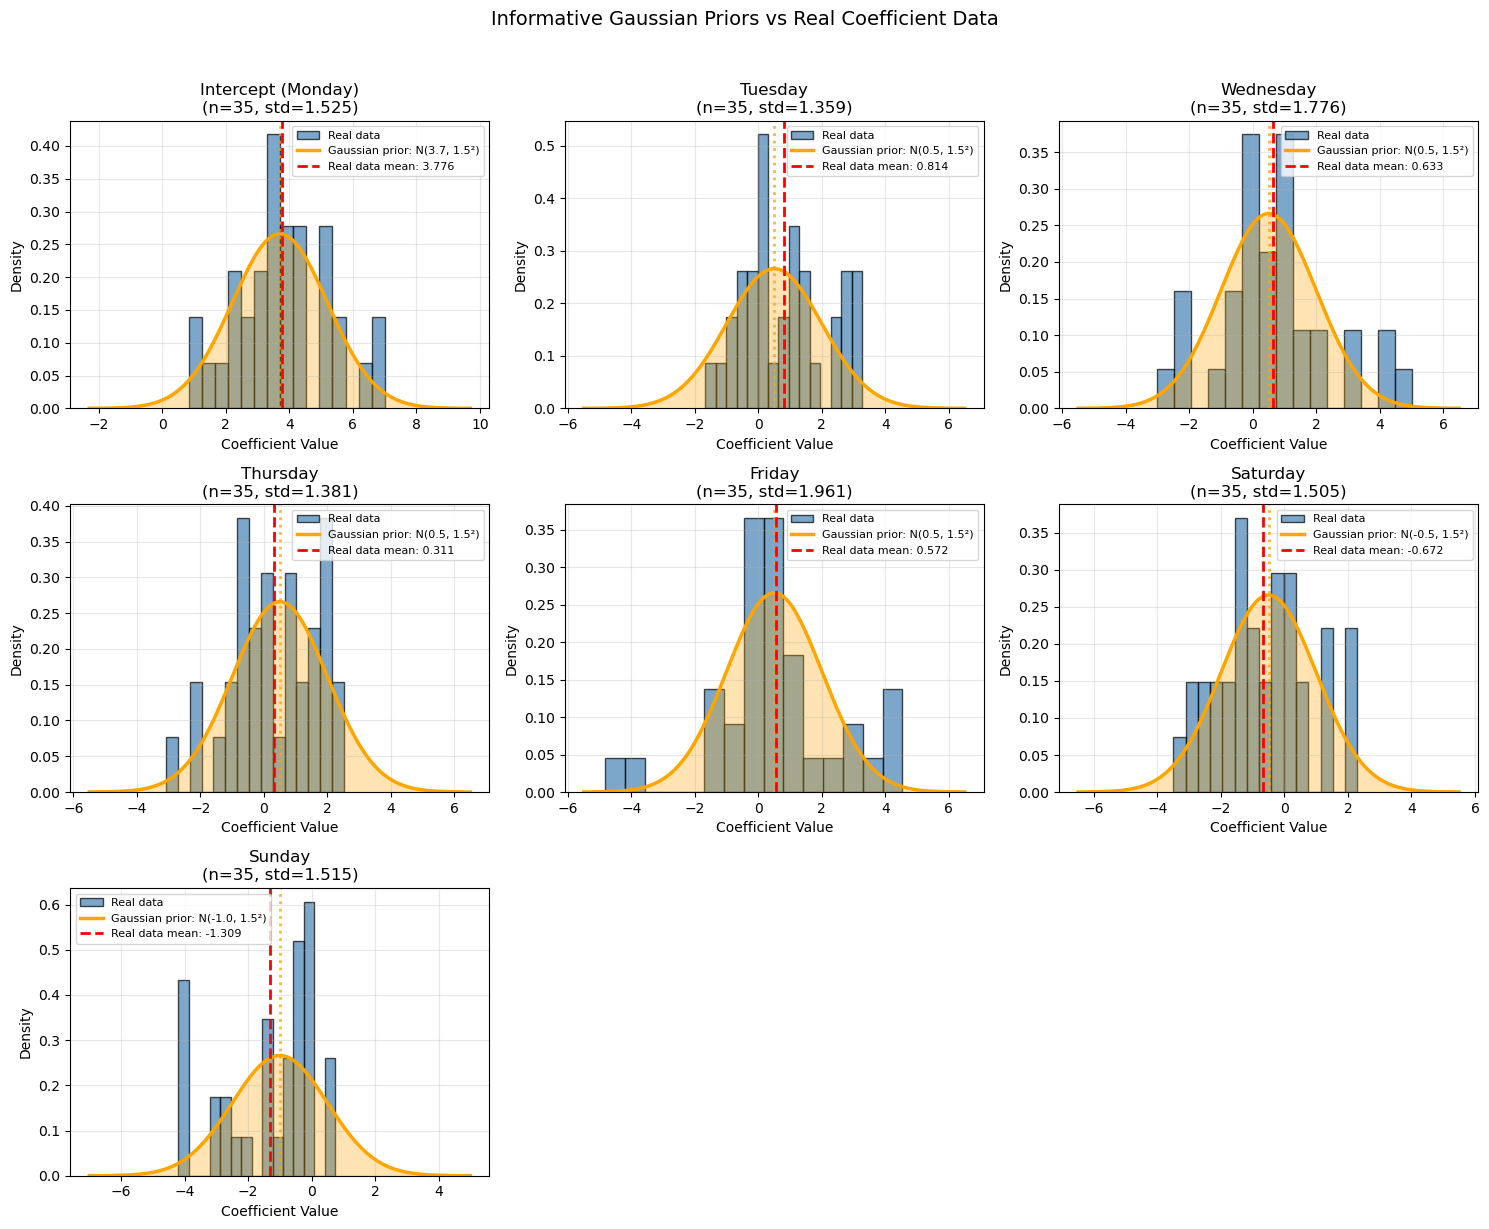


Comparison of Gaussian Priors vs Real Data:
       Coefficient  Prior Mean  Prior Std  Real Data Mean  Real Data Std  Difference (Mean)
Intercept (Monday)         3.7        1.5        3.775749       1.524925          -0.075749
           Tuesday         0.5        1.5        0.814028       1.358652          -0.314028
         Wednesday         0.5        1.5        0.632641       1.775505          -0.132641
          Thursday         0.5        1.5        0.310619       1.381397           0.189381
            Friday         0.5        1.5        0.571706       1.960578          -0.071706
          Saturday        -0.5        1.5       -0.672304       1.505317           0.172304
            Sunday        -1.0        1.5       -1.309168       1.514692           0.309168


In [23]:
# Plot informative Gaussian priors vs real coefficient data (no fitted data)
from scipy.stats import norm

# Informative priors from cell 21
prior_means_map = {
    'Intercept': 3.7,  # Monday baseline
    'C(weekday, Treatment(reference="Monday"))[T.Tuesday]': 0.5,
    'C(weekday, Treatment(reference="Monday"))[T.Wednesday]': 0.5,
    'C(weekday, Treatment(reference="Monday"))[T.Thursday]': 0.5,
    'C(weekday, Treatment(reference="Monday"))[T.Friday]': 0.5,
    'C(weekday, Treatment(reference="Monday"))[T.Saturday]': -0.5,
    'C(weekday, Treatment(reference="Monday"))[T.Sunday]': -1.0
}

# Short names for display
short_names = {
    'Intercept': 'Intercept (Monday)',
    'C(weekday, Treatment(reference="Monday"))[T.Tuesday]': 'Tuesday',
    'C(weekday, Treatment(reference="Monday"))[T.Wednesday]': 'Wednesday',
    'C(weekday, Treatment(reference="Monday"))[T.Thursday]': 'Thursday',
    'C(weekday, Treatment(reference="Monday"))[T.Friday]': 'Friday',
    'C(weekday, Treatment(reference="Monday"))[T.Saturday]': 'Saturday',
    'C(weekday, Treatment(reference="Monday"))[T.Sunday]': 'Sunday'
}

prior_std = 1.5  # Prior standard deviation

# Filter to only weekday coefficients (exclude intervention_period)
weekday_coefs = [col for col in coefficients_df.columns if col in prior_means_map]

# Create figure with subplots
n_coefs = len(weekday_coefs)
n_cols = 3
n_rows = (n_coefs + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows))
axes = axes.flatten()

# Colors
data_color = 'steelblue'
prior_color = 'orange'

# Plot each coefficient
for idx, coef_name in enumerate(weekday_coefs):
    ax = axes[idx]
    
    # Get real coefficient values from the data
    coef_values = coefficients_df[coef_name].dropna()
    
    # Plot histogram of real coefficients
    n, bins, patches = ax.hist(coef_values, bins=15, edgecolor='black', alpha=0.7, 
                               color=data_color, density=True, label='Real data')
    
    # Overlay Gaussian prior
    prior_mean = prior_means_map[coef_name]
    x_min = min(coef_values.min(), prior_mean - 4 * prior_std)
    x_max = max(coef_values.max(), prior_mean + 4 * prior_std)
    x = np.linspace(x_min, x_max, 1000)
    
    prior_pdf = norm.pdf(x, loc=prior_mean, scale=prior_std)
    ax.plot(x, prior_pdf, color=prior_color, linewidth=2.5, 
            label=f'Gaussian prior: N({prior_mean:.1f}, {prior_std:.1f}²)')
    
    # Shade the prior distribution
    ax.fill_between(x, prior_pdf, alpha=0.3, color=prior_color)
    
    # Mark the prior mean and real data mean
    ax.axvline(prior_mean, color=prior_color, linestyle=':', linewidth=2, alpha=0.8)
    ax.axvline(coef_values.mean(), color='red', linestyle='--', linewidth=2, 
               label=f'Real data mean: {coef_values.mean():.3f}')
    
    ax.set_xlabel('Coefficient Value')
    ax.set_ylabel('Density')
    ax.set_title(f'{short_names[coef_name]}\n(n={len(coef_values)}, std={coef_values.std():.3f})')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

# Hide unused subplots
for idx in range(n_coefs, len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Informative Gaussian Priors vs Real Coefficient Data', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Print comparison
print("\nComparison of Gaussian Priors vs Real Data:")
print("=" * 80)
comparison_data = []
for coef_name in weekday_coefs:
    coef_values = coefficients_df[coef_name].dropna()
    comparison_data.append({
        'Coefficient': short_names[coef_name],
        'Prior Mean': prior_means_map[coef_name],
        'Prior Std': prior_std,
        'Real Data Mean': coef_values.mean(),
        'Real Data Std': coef_values.std(),
        'Difference (Mean)': prior_means_map[coef_name] - coef_values.mean()
    })

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))


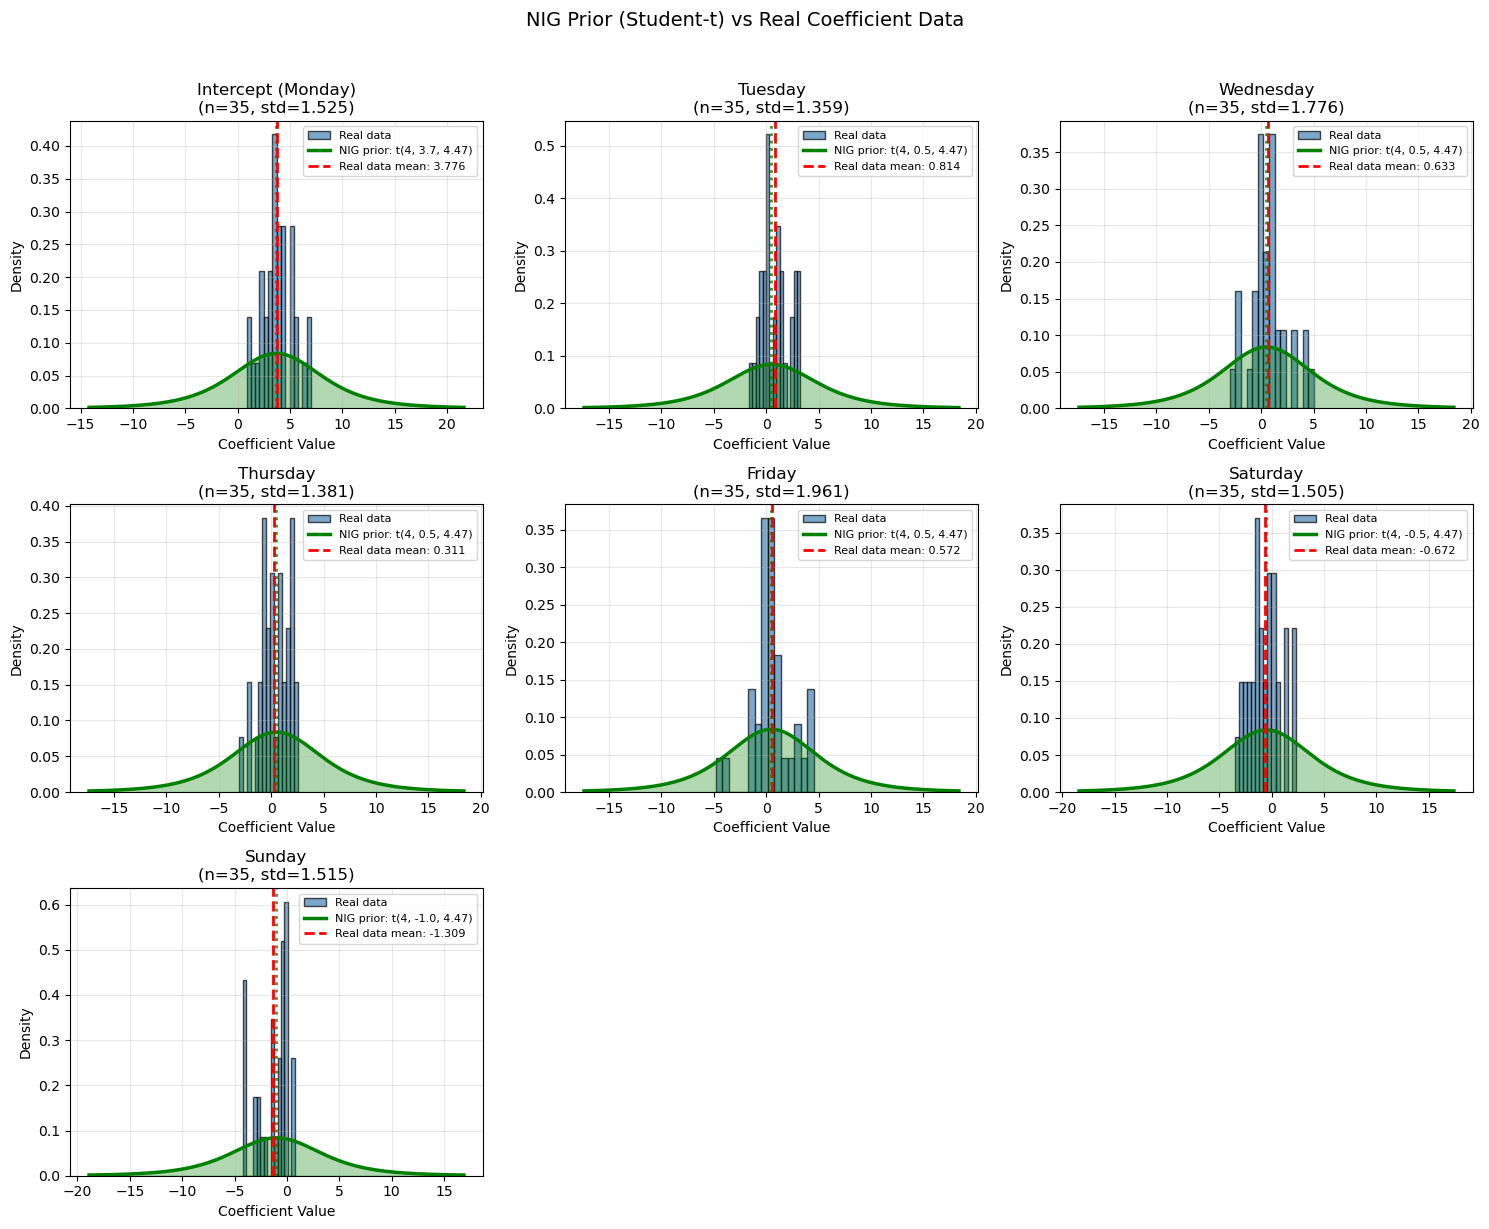


NIG Prior Parameters:
Degrees of freedom (df): 4.0
Scale parameter: 4.4721
Inverse-gamma: a=2.0, b=4.0
V matrix diagonal: 10.0

Comparison of NIG Prior vs Real Data:
       Coefficient  NIG Prior Mean  NIG Prior Scale  Real Data Mean  Real Data Std  Difference (Mean)
Intercept (Monday)             3.7         4.472136        3.775749       1.524925          -0.075749
           Tuesday             0.5         4.472136        0.814028       1.358652          -0.314028
         Wednesday             0.5         4.472136        0.632641       1.775505          -0.132641
          Thursday             0.5         4.472136        0.310619       1.381397           0.189381
            Friday             0.5         4.472136        0.571706       1.960578          -0.071706
          Saturday            -0.5         4.472136       -0.672304       1.505317           0.172304
            Sunday            -1.0         4.472136       -1.309168       1.514692           0.309168


In [24]:
# Plot NIG prior vs real coefficient data
from scipy.stats import norm, t as student_t

# NIG prior parameters (from cell 23)
nig_prior_means = np.array([
    3.7,   # Intercept (Monday baseline)
    0.5,   # Tuesday
    0.5,   # Wednesday
    0.5,   # Thursday
    0.5,   # Friday
    -0.5,  # Saturday
    -1.0   # Sunday
])

nig_prior_cov_diag = 10.0  # V matrix diagonal
nig_prior_a = 2.0
nig_prior_b = 4.0

# For NIG model, the marginal prior for each coefficient is Student-t
# β_i ~ t(df=2a, loc=μ_i, scale=sqrt(b/a * V_ii))
nig_prior_df = 2 * nig_prior_a  # degrees of freedom = 4
nig_prior_scale = np.sqrt(nig_prior_b / nig_prior_a * nig_prior_cov_diag)  # scale parameter

# Map to coefficient names
coef_names = ['Intercept (Monday)', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Map to coefficients_df column names
coef_mapping = {
    'Intercept (Monday)': 'Intercept',
    'Tuesday': 'C(weekday, Treatment(reference="Monday"))[T.Tuesday]',
    'Wednesday': 'C(weekday, Treatment(reference="Monday"))[T.Wednesday]',
    'Thursday': 'C(weekday, Treatment(reference="Monday"))[T.Thursday]',
    'Friday': 'C(weekday, Treatment(reference="Monday"))[T.Friday]',
    'Saturday': 'C(weekday, Treatment(reference="Monday"))[T.Saturday]',
    'Sunday': 'C(weekday, Treatment(reference="Monday"))[T.Sunday]'
}

# Filter to only weekday coefficients that exist in coefficients_df
available_coefs = [(name, coef_mapping[name]) for name in coef_names 
                   if coef_mapping[name] in coefficients_df.columns]

# Create figure with subplots
n_coefs = len(available_coefs)
n_cols = 3
n_rows = (n_coefs + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows))
axes = axes.flatten()

# Colors
data_color = 'steelblue'
nig_prior_color = 'green'

# Plot each coefficient
for idx, (display_name, coef_name) in enumerate(available_coefs):
    ax = axes[idx]
    
    # Get real coefficient values from the data
    coef_values = coefficients_df[coef_name].dropna()
    
    # Get NIG prior parameters for this coefficient
    nig_prior_mean = nig_prior_means[idx]
    
    # Plot histogram of real coefficients
    n, bins, patches = ax.hist(coef_values, bins=15, edgecolor='black', alpha=0.7, 
                               color=data_color, density=True, label='Real data')
    
    # Plot NIG prior (Student-t distribution)
    x_min = min(coef_values.min(), nig_prior_mean - 4 * nig_prior_scale)
    x_max = max(coef_values.max(), nig_prior_mean + 4 * nig_prior_scale)
    x = np.linspace(x_min, x_max, 1000)
    
    nig_prior_pdf = student_t.pdf(x, df=nig_prior_df, loc=nig_prior_mean, scale=nig_prior_scale)
    ax.plot(x, nig_prior_pdf, color=nig_prior_color, linewidth=2.5, 
            label=f'NIG prior: t({nig_prior_df:.0f}, {nig_prior_mean:.1f}, {nig_prior_scale:.2f})')
    
    # Shade the prior distribution
    ax.fill_between(x, nig_prior_pdf, alpha=0.3, color=nig_prior_color)
    
    # Mark the prior mean and real data mean
    ax.axvline(nig_prior_mean, color=nig_prior_color, linestyle=':', linewidth=2, alpha=0.8)
    ax.axvline(coef_values.mean(), color='red', linestyle='--', linewidth=2, 
               label=f'Real data mean: {coef_values.mean():.3f}')
    
    ax.set_xlabel('Coefficient Value')
    ax.set_ylabel('Density')
    ax.set_title(f'{display_name}\n(n={len(coef_values)}, std={coef_values.std():.3f})')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

# Hide unused subplots
for idx in range(n_coefs, len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('NIG Prior (Student-t) vs Real Coefficient Data', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Print NIG prior parameters
print("\nNIG Prior Parameters:")
print("=" * 80)
print(f"Degrees of freedom (df): {nig_prior_df}")
print(f"Scale parameter: {nig_prior_scale:.4f}")
print(f"Inverse-gamma: a={nig_prior_a}, b={nig_prior_b}")
print(f"V matrix diagonal: {nig_prior_cov_diag}")
print(f"\nComparison of NIG Prior vs Real Data:")
print("=" * 80)
comparison_data = []
for idx, (display_name, coef_name) in enumerate(available_coefs):
    coef_values = coefficients_df[coef_name].dropna()
    comparison_data.append({
        'Coefficient': display_name,
        'NIG Prior Mean': nig_prior_means[idx],
        'NIG Prior Scale': nig_prior_scale,
        'Real Data Mean': coef_values.mean(),
        'Real Data Std': coef_values.std(),
        'Difference (Mean)': nig_prior_means[idx] - coef_values.mean()
    })

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))


In [26]:
# Define weakly informative and highly informative priors for NIG model
import numpy as np
import pandas as pd

# Coefficient names
coef_names = ['Intercept (Monday)', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
n_coefs = len(coef_names)

# ============================================================================
# WEAKLY INFORMATIVE PRIORS
# ============================================================================
weakly_informative_priors = {
    'name': 'Weakly Informative',
    'means': np.zeros(n_coefs),  # Centered at zero
    'cov_diag': 100.0,  # Large covariance = high uncertainty
    'a': 1.0,  # Small a = vague prior on variance
    'b': 1.0,  # Small b = vague prior on variance
    'description': 'Weakly informative: centered at 0, large uncertainty'
}

# ============================================================================
# HIGHLY INFORMATIVE PRIORS
# ============================================================================
highly_informative_priors = {
    'name': 'Highly Informative',
    'means': np.array([
        3.7,   # Intercept (Monday baseline) - from data analysis
        0.5,   # Tuesday - from data analysis
        0.5,   # Wednesday - from data analysis
        0.5,   # Thursday - from data analysis
        0.5,   # Friday - from data analysis
        -0.5,  # Saturday - from data analysis
        -1.0   # Sunday - from data analysis
    ]),
    'cov_diag': 1.0,  # Small covariance = low uncertainty
    'a': 5.0,  # Larger a = more informative prior on variance
    'b': 16.0,  # Larger b = more informative prior on variance (E[σ²] = b/(a-1) = 16/4 = 4)
    'description': 'Highly informative: based on data analysis, low uncertainty'
}

# Calculate effective marginal prior stds for both
for prior_set in [weakly_informative_priors, highly_informative_priors]:
    expected_sigma2 = prior_set['b'] / (prior_set['a'] - 1) if prior_set['a'] > 1 else prior_set['b']
    effective_std = np.sqrt(expected_sigma2 * prior_set['cov_diag'])
    prior_set['expected_sigma2'] = expected_sigma2
    prior_set['effective_marginal_std'] = effective_std

# Print both sets of priors
print("=" * 80)
print("PRIOR SPECIFICATIONS FOR NIG MODEL")
print("=" * 80)

for prior_set in [weakly_informative_priors, highly_informative_priors]:
    print(f"\n{prior_set['name'].upper()} PRIORS")
    print("-" * 80)
    print(f"Description: {prior_set['description']}")
    print(f"\nPrior Means (μ):")
    for i, name in enumerate(coef_names):
        print(f"  {name:20s}: {prior_set['means'][i]:8.3f}")
    
    print(f"\nPrior Covariance Matrix V:")
    print(f"  Diagonal value: {prior_set['cov_diag']:.2f}")
    print(f"  (V is a {n_coefs}x{n_coefs} diagonal matrix with {prior_set['cov_diag']:.2f} on diagonal)")
    
    print(f"\nInverse-Gamma Prior for σ²:")
    print(f"  Shape parameter (a): {prior_set['a']:.2f}")
    print(f"  Scale parameter (b): {prior_set['b']:.2f}")
    print(f"  E[σ²] = b/(a-1) = {prior_set['expected_sigma2']:.4f}")
    print(f"  E[σ] = {np.sqrt(prior_set['expected_sigma2']):.4f}")
    
    print(f"\nMarginal Prior for Coefficients β:")
    print(f"  Distribution: Student-t(df={2*prior_set['a']:.0f}, μ, scale)")
    print(f"  Scale = sqrt(b/a * V) = sqrt({prior_set['b']:.2f}/{prior_set['a']:.2f} * {prior_set['cov_diag']:.2f}) = {np.sqrt(prior_set['b']/prior_set['a'] * prior_set['cov_diag']):.4f}")
    print(f"  Effective marginal std ≈ {prior_set['effective_marginal_std']:.4f}")

# Create comparison table
print("\n" + "=" * 80)
print("COMPARISON TABLE")
print("=" * 80)

comparison_data = []
for i, name in enumerate(coef_names):
    comparison_data.append({
        'Coefficient': name,
        'Weakly Inf. Mean': weakly_informative_priors['means'][i],
        'Highly Inf. Mean': highly_informative_priors['means'][i],
        'Difference': highly_informative_priors['means'][i] - weakly_informative_priors['means'][i]
    })

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

print("\n" + "=" * 80)
print("PRIOR PARAMETER COMPARISON")
print("=" * 80)
param_comparison = pd.DataFrame({
    'Parameter': ['Covariance V (diagonal)', 'Inverse-Gamma a', 'Inverse-Gamma b', 
                  'Expected σ²', 'Effective Marginal Std'],
    'Weakly Informative': [
        weakly_informative_priors['cov_diag'],
        weakly_informative_priors['a'],
        weakly_informative_priors['b'],
        weakly_informative_priors['expected_sigma2'],
        weakly_informative_priors['effective_marginal_std']
    ],
    'Highly Informative': [
        highly_informative_priors['cov_diag'],
        highly_informative_priors['a'],
        highly_informative_priors['b'],
        highly_informative_priors['expected_sigma2'],
        highly_informative_priors['effective_marginal_std']
    ]
})
print(param_comparison.to_string(index=False))


PRIOR SPECIFICATIONS FOR NIG MODEL

WEAKLY INFORMATIVE PRIORS
--------------------------------------------------------------------------------
Description: Weakly informative: centered at 0, large uncertainty

Prior Means (μ):
  Intercept (Monday)  :    0.000
  Tuesday             :    0.000
  Wednesday           :    0.000
  Thursday            :    0.000
  Friday              :    0.000
  Saturday            :    0.000
  Sunday              :    0.000

Prior Covariance Matrix V:
  Diagonal value: 100.00
  (V is a 7x7 diagonal matrix with 100.00 on diagonal)

Inverse-Gamma Prior for σ²:
  Shape parameter (a): 1.00
  Scale parameter (b): 1.00
  E[σ²] = b/(a-1) = 1.0000
  E[σ] = 1.0000

Marginal Prior for Coefficients β:
  Distribution: Student-t(df=2, μ, scale)
  Scale = sqrt(b/a * V) = sqrt(1.00/1.00 * 100.00) = 10.0000
  Effective marginal std ≈ 10.0000

HIGHLY INFORMATIVE PRIORS
--------------------------------------------------------------------------------
Description: Highly info